
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/11_Lab_LagevineII_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


In [ ]:

# Tamaño del sistema
N = 8

# Distribución normal estándar
Zr = stats.norm(loc=0, scale=1)

# Generación de N² variables aleatorias
Z = Zr.rvs(size=N*N, random_state=42)

print(f"Número de variables: {Z.size}")
print(f"Media muestral: {Z.mean():.4f}")
print(f"Desviación estándar muestral: {Z.std():.4f}")


Número de variables: 64
Media muestral: -0.1914
Desviación estándar muestral: 0.8901


In [ ]:

# Intensidad del ruido
sigma = 0.5

# Escalamiento de las variables gaussianas
epsilon = sigma * Z

# Variable utilizada en los cálculos posteriores
e = epsilon

print(f"Media del ruido: {e.mean():.4f}")
print(f"Desviación estándar: {e.std():.4f}")
print(f"Número de elementos: {e.size}")


Media del ruido: -0.0957
Desviación estándar: 0.4451
Número de elementos: 64


In [ ]:
np.std(epsilon)

np.float64(0.44506771467383444)

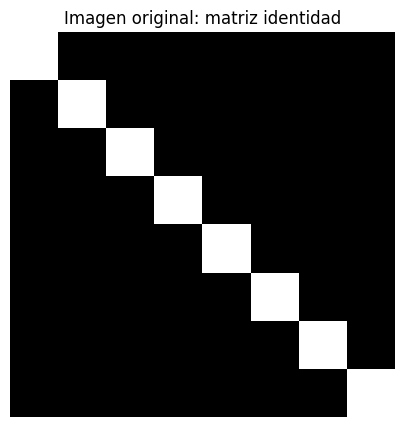

Dimensión de la matriz: (8, 8)
Dimensión del vector: (64,)


In [ ]:

# Construcción de la matriz identidad
X = np.eye(N)

# Conversión de matriz a vector
x = X.flatten()

# Visualización de la imagen
plt.figure(figsize=(5, 5))
plt.imshow(X, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
plt.title("Imagen original: matriz identidad")
plt.axis("off")
plt.show()

print(f"Dimensión de la matriz: {X.shape}")
print(f"Dimensión del vector: {x.shape}")



ENTRADA:
    Imágenes originales X
    Niveles de ruido sigma

1. Normalizar las imágenes.
2. Separar entrenamiento y evaluación.
3. Inicializar la red neuronal s_theta.

PARA cada iteración:

    Seleccionar un lote de imágenes x.
    Seleccionar un nivel de ruido sigma > 0.

    Generar ruido gaussiano:
        epsilon = sigma * Normal(0, I)

    Construir imágenes perturbadas:
        y = x + epsilon

    Calcular el score objetivo:
        S_objetivo = -epsilon / sigma**2

    Predecir el score:
        S_predicho = s_theta(y, sigma)

    Calcular la pérdida:
        L = 0.5 * promedio(
            ||S_predicho - S_objetivo||²
        )

    Actualizar los parámetros theta.

4. Evaluar con datos reservados.

SALIDA:
    Campo aprendido s_theta(y, sigma)


In [ ]:
#x = np.array([0.2, 0.8, 0.4, 0.6])
#e

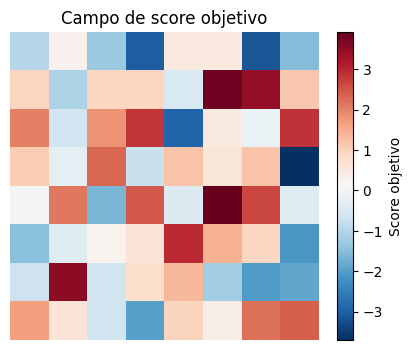

In [ ]:

# Cálculo del score objetivo
Sobjetivo = -e / sigma**2

# Visualización del campo
plt.figure(figsize=(5, 4))
plt.imshow(Sobjetivo.reshape(N, N), cmap="RdBu_r")
plt.colorbar(label="Score objetivo")
plt.title("Campo de score objetivo")
plt.axis("off")
plt.show()


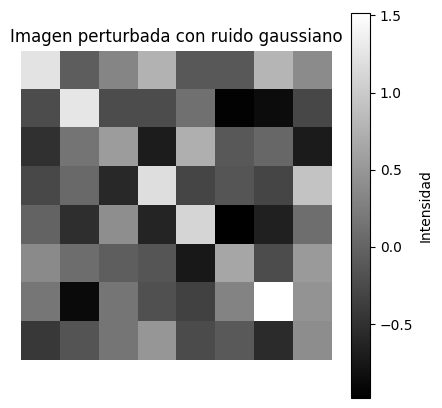

In [ ]:

# Añadir ruido gaussiano a la imagen original
xp = x + e

# Visualización
plt.figure(figsize=(5, 5))
plt.imshow(xp.reshape(N, N), cmap="gray")
plt.colorbar(label="Intensidad")
plt.title("Imagen perturbada con ruido gaussiano")
plt.axis("off")
plt.show()


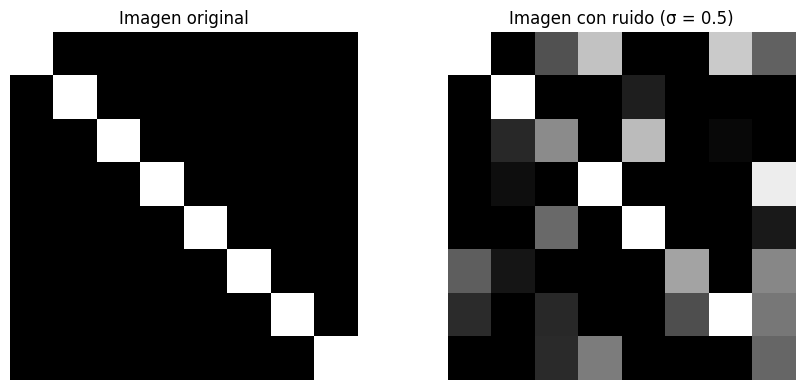

In [ ]:

# Imagen perturbada
xp = x + e

fig, ax = plt.subplots(1, 2, figsize=(9, 4))

ax[0].imshow(X, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Imagen original")
ax[0].axis("off")

ax[1].imshow(xp.reshape(N, N), cmap="gray",
             vmin=0, vmax=1, interpolation="nearest")
ax[1].set_title(f"Imagen con ruido (σ = {sigma})")
ax[1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Parámetros del ruido
sigma = 0.2

# Parámetros iniciales del modelo
A = 0.0
B = 0.0

# Tasas de aprendizaje
alphaA = 0.01
alphaB = 0.01

# Generador aleatorio
rng = np.random.default_rng(42)

# Historial de la pérdida
historial_loss = []

# Entrenamiento
for i in range(50000):

    # Generar nuevo ruido gaussiano
    e = rng.normal(0, sigma, size=x.shape)

    # Imagen perturbada
    xp = x + e

    # Score objetivo
    Sobjetivo = -e / sigma**2

    # Modelo lineal
    Spredicho = A * xp + B

    # Error
    error = Spredicho - Sobjetivo

    # Función de pérdida
    Loss = 0.5 * np.mean(error**2)

    # Gradientes
    gradA = np.mean(error * xp)
    gradB = np.mean(error)

    # Actualización de parámetros
    A -= alphaA * gradA
    B -= alphaB * gradB

    historial_loss.append(Loss)

print(f"Pérdida final: {Loss:.6f}")
print(f"Parámetro A: {A:.6f}")
print(f"Parámetro B: {B:.6f}")




Pérdida final: 9.410365
Parámetro A: -6.650522
Parámetro B: 0.879120


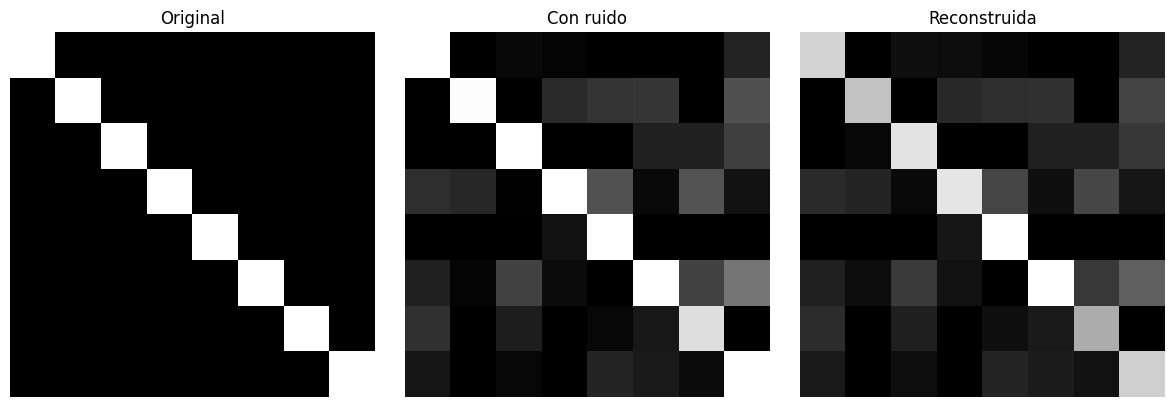

Error cuadrático medio: 0.021946


In [ ]:

# Generar una nueva imagen perturbada
e_test = rng.normal(0, sigma, size=x.shape)
xp_test = x + e_test

# Calcular el score con el modelo entrenado
Spredicho_test = A * xp_test + B

# Reconstrucción de la imagen
Y = xp_test + sigma**2 * Spredicho_test

# Comparación visual
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

imagenes = [x, xp_test, Y]
titulos = ["Original", "Con ruido", "Reconstruida"]

for a, imagen, titulo in zip(ax, imagenes, titulos):
    a.imshow(imagen.reshape(N, N), cmap="gray",
             vmin=0, vmax=1, interpolation="nearest")
    a.set_title(titulo)
    a.axis("off")

plt.tight_layout()
plt.show()

# Error de reconstrucción
mse = np.mean((Y - x)**2)
print(f"Error cuadrático medio: {mse:.6f}")




In [ ]:

# Error antes de la reconstrucción
mse_ruido = np.mean((xp_test - x)**2)

# Error después de la reconstrucción
mse_reconstruido = np.mean((Y - x)**2)

# Porcentaje de reducción del error
mejora = 100 * (1 - mse_reconstruido / mse_ruido)

print(f"MSE con ruido:       {mse_ruido:.6f}")
print(f"MSE reconstruido:    {mse_reconstruido:.6f}")
print(f"Reducción del error: {mejora:.2f}%")


MSE con ruido:       0.034657
MSE reconstruido:    0.021946
Reducción del error: 36.68%


ENTRADA: imagen perturbada y, nivel de ruido σ,
         campo aprendido sθ

Calcular el campo: S = sθ(y, σ)

Estimar la imagen limpia:
    x_estimada = y + σ² · S

Si conocemos la imagen original:
    Comparar la estimación con ella
    Calcular el error de recuperación

SALIDA: imagen limpia estimada

In [ ]:

# 1. Generar una nueva imagen perturbada
rng_prueba = np.random.default_rng(123)

e_prueba = rng_prueba.normal(0, sigma, size=x.shape)
x_prueba = x + e_prueba

# 2. Evaluar el campo aprendido
S_prueba = A * x_prueba + B

# 3. Reconstruir la imagen
x_recuperado = x_prueba + sigma**2 * S_prueba

# 4. Comprobar la reducción del error
mse_ruido = np.mean((x_prueba - x)**2)
mse_recuperado = np.mean((x_recuperado - x)**2)

print(f"MSE con ruido:    {mse_ruido:.6f}")
print(f"MSE recuperado:   {mse_recuperado:.6f}")
print(f"Mejora: {100 * (1 - mse_recuperado/mse_ruido):.2f}%")


MSE con ruido:    0.034530
MSE recuperado:   0.028517
Mejora: 17.42%


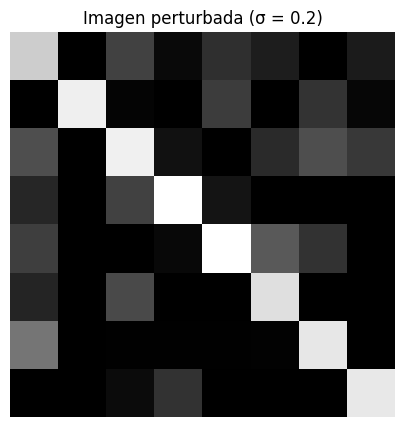

In [ ]:

plt.figure(figsize=(5, 5))

plt.imshow(
    x_prueba.reshape(N, N),
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

plt.title(f"Imagen perturbada (σ = {sigma})")
plt.axis("off")
plt.show()


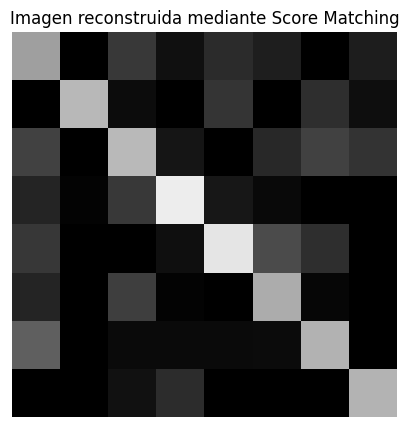

In [ ]:

plt.figure(figsize=(5, 5))

plt.imshow(
    x_recuperado.reshape(N, N),
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

plt.title("Imagen reconstruida mediante Score Matching")
plt.axis("off")
plt.show()


# Langevine

ENTRADA: campo aprendido, niveles σ de mayor a menor,
         número de pasos K y constante pequeña c

Inicializar desde ruido:
    Y = μ + σ_max · Normal(0, I)
    μ es la media de las imágenes de entrenamiento

PARA cada nivel σ, desde σ_max hasta σ_min:
    Elegir el paso: h = c · σ²

    REPETIR K veces:
        Calcular el campo: S = sθ(Y, σ)
        Generar ruido nuevo: Z = Normal(0, I)

        Actualizar mediante Langevin:
            Y = Y + h · S + √(2h) · Z

Opcionalmente aplicar la recuperación final:
    Y = Y + σ_min² · sθ(Y, σ_min)

SALIDA: imagen generada

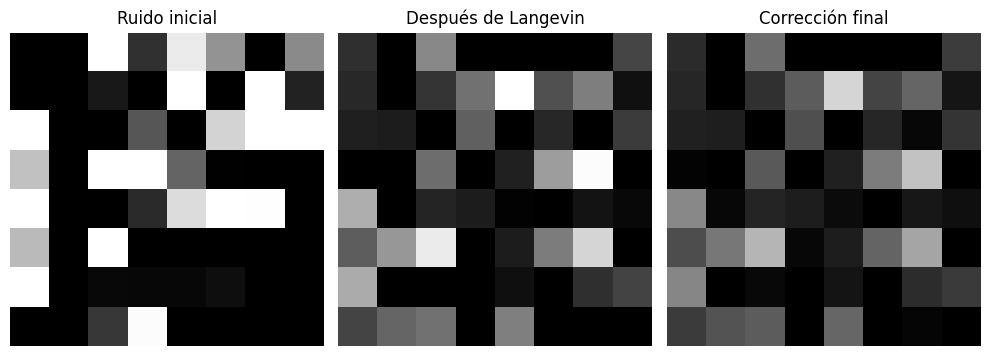

A = -6.65052
B = 0.87912
Estabilidad aproximada: 0.99335


In [ ]:

# Generador reproducible
rng_generacion = np.random.default_rng(123)

# Inicialización desde ruido gaussiano
Y = rng_generacion.normal(0, 1, size=x.shape)
Y_inicial = Y.copy()

# Parámetros de Langevin
dt = 0.001
n_pasos = 1000

# Evolución estocástica
for paso in range(n_pasos):

    # Campo aprendido
    S = A * Y + B

    # Ruido gaussiano independiente
    Z = rng_generacion.normal(0, 1, size=Y.shape)

    # Actualización de Langevin
    Y = Y + dt*S + np.sqrt(2*dt)*Z

# Corrección final opcional
Y_recuperada = Y + sigma**2 * (A*Y + B)

# Visualización
fig, ejes = plt.subplots(1, 3, figsize=(10, 3.5))

imagenes = [Y_inicial, Y, Y_recuperada]
titulos = [
    "Ruido inicial",
    "Después de Langevin",
    "Corrección final"
]

for eje, imagen, titulo in zip(ejes, imagenes, titulos):
    eje.imshow(
        imagen.reshape(N, N),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

print(f"A = {A:.5f}")
print(f"B = {B:.5f}")
print(f"Estabilidad aproximada: {abs(1 + dt*A):.5f}")


# Caso con más imagenes

In [ ]:
%pip -q install datasets

In [ ]:

from datasets import load_dataset
import numpy as np

# Cargar CIFAR-10 en modo streaming
datos = load_dataset(
    "uoft-cs/cifar10",
    split="train",
    streaming=True
)

# Seleccionar imágenes de perros
perros = []
n_imagenes = 1000

for ejemplo in datos:
    if ejemplo["label"] == 5:  # Clase perro
        imagen = np.asarray(
            ejemplo["img"].convert("RGB"),
            dtype=np.float32
        ) / 255.0

        perros.append(imagen)

        if len(perros) % 100 == 0:
            print(f"Cargadas: {len(perros)} imágenes")

        if len(perros) >= n_imagenes:
            break

# Convertir a un arreglo de NumPy
perros = np.stack(perros)

print("Dimensiones:", perros.shape)
print("Intensidades:", perros.min(), perros.max())


Cargadas: 100 imágenes
Cargadas: 200 imágenes
Cargadas: 300 imágenes
Cargadas: 400 imágenes
Cargadas: 500 imágenes
Cargadas: 600 imágenes
Cargadas: 700 imágenes
Cargadas: 800 imágenes
Cargadas: 900 imágenes
Cargadas: 1000 imágenes
Dimensiones: (1000, 32, 32, 3)
Intensidades: 0.0 1.0


Forma del conjunto: (1000, 32, 32, 3)


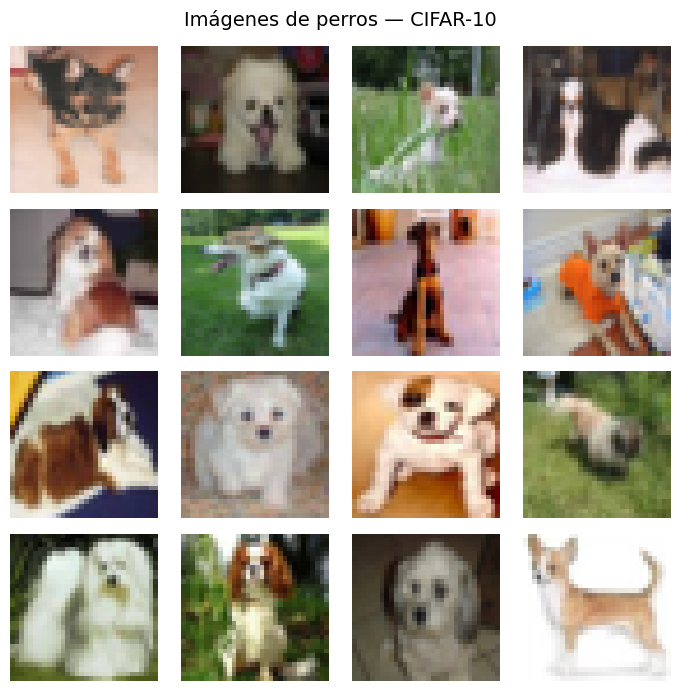

In [ ]:

# Utilizar el conjunto de imágenes normalizadas
X_perros = perros

print("Forma del conjunto:", X_perros.shape)

# Visualizar las primeras 16 imágenes
fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for ax, imagen in zip(axes.ravel(), X_perros[:16]):
    ax.imshow(imagen)
    ax.axis("off")

fig.suptitle("Imágenes de perros — CIFAR-10", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:

# Normalización de [0, 1] a [-1, 1]
X_entrenamiento = 2.0 * X_perros.astype(np.float32) - 1.0

# Verificación
print("Dimensiones:", X_entrenamiento.shape)
print("Valor mínimo:", X_entrenamiento.min())
print("Valor máximo:", X_entrenamiento.max())


Dimensiones: (1000, 32, 32, 3)
Valor mínimo: -1.0
Valor máximo: 1.0


In [ ]:

# Parámetros
rng = np.random.default_rng(42)
sigma = 0.3

# Generar ruido gaussiano
epsilon = rng.normal(
    loc=0.0,
    scale=sigma,
    size=X_entrenamiento.shape
).astype(np.float32)

# Construir imágenes perturbadas
X_ruidosas = X_entrenamiento + epsilon

# Calcular el score objetivo
S_objetivo = -epsilon / sigma**2

# Verificaciones
print("Imágenes limpias:", X_entrenamiento.shape)
print("Imágenes ruidosas:", X_ruidosas.shape)
print("Score objetivo:", S_objetivo.shape)
print(f"Desviación estándar del ruido: {epsilon.std():.4f}")


Imágenes limpias: (1000, 32, 32, 3)
Imágenes ruidosas: (1000, 32, 32, 3)
Score objetivo: (1000, 32, 32, 3)
Desviación estándar del ruido: 0.3000


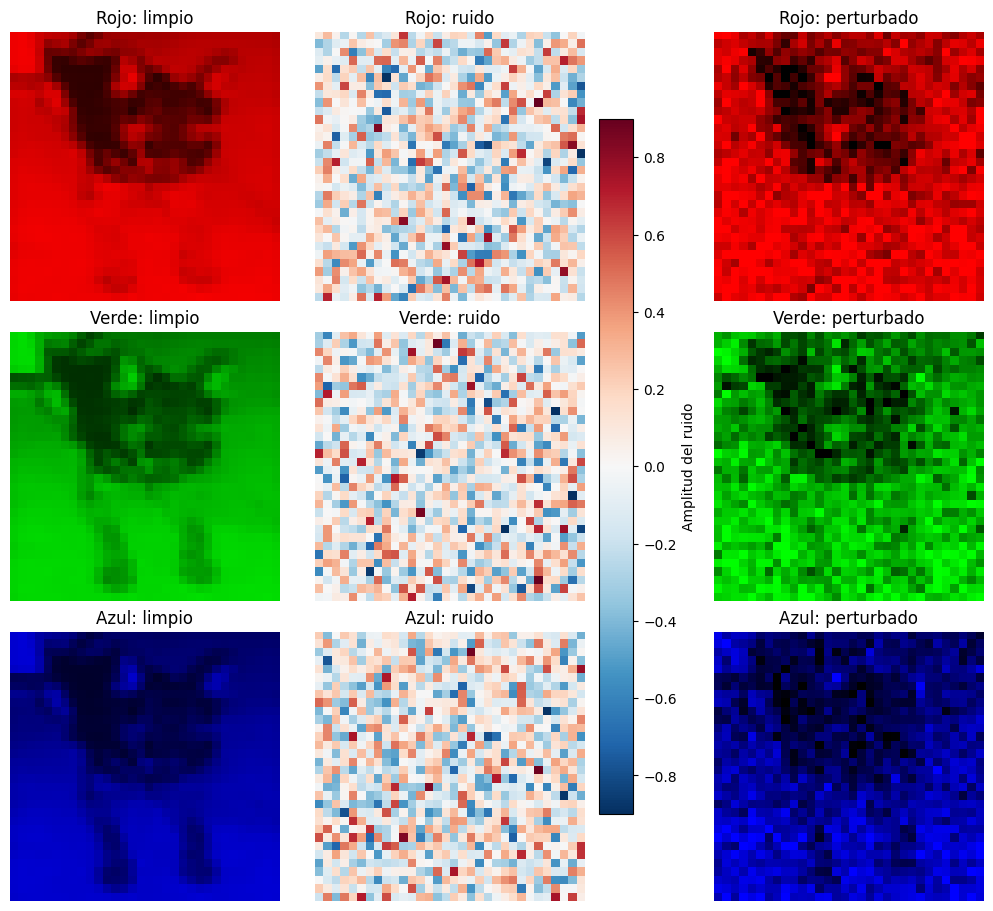

In [ ]:

# Seleccionar imagen
i = 0

# Convertir imágenes de [-1, 1] a [0, 1] para visualización
limpia = np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
ruidosa = np.clip((X_ruidosas[i] + 1) / 2, 0, 1)

nombres = ["Rojo", "Verde", "Azul"]

fig, axes = plt.subplots(
    3, 3, figsize=(10, 9), constrained_layout=True
)

for canal, nombre in enumerate(nombres):

    # Canal limpio
    limpia_canal = np.zeros_like(limpia)
    limpia_canal[:, :, canal] = limpia[:, :, canal]

    # Canal perturbado
    ruidosa_canal = np.zeros_like(ruidosa)
    ruidosa_canal[:, :, canal] = ruidosa[:, :, canal]

    axes[canal, 0].imshow(limpia_canal)
    axes[canal, 0].set_title(f"{nombre}: limpio")

    # Ruido añadido
    im = axes[canal, 1].imshow(
        epsilon[i, :, :, canal],
        cmap="RdBu_r",
        vmin=-3*sigma,
        vmax=3*sigma,
        interpolation="nearest"
    )
    axes[canal, 1].set_title(f"{nombre}: ruido")

    axes[canal, 2].imshow(ruidosa_canal)
    axes[canal, 2].set_title(f"{nombre}: perturbado")

for ax in axes.ravel():
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[:, 1].tolist(),
    shrink=0.8,
    label="Amplitud del ruido"
)

plt.show()


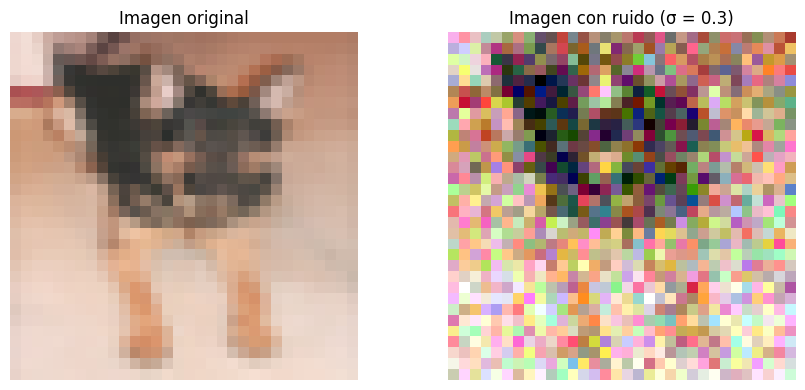

In [ ]:

# Seleccionar una imagen
i = 0

# Preparar imágenes para visualización
imagen_limpia = np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
imagen_ruidosa = np.clip((X_ruidosas[i] + 1) / 2, 0, 1)

# Comparación visual
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(imagen_limpia, interpolation="nearest")
axes[0].set_title("Imagen original")

axes[1].imshow(imagen_ruidosa, interpolation="nearest")
axes[1].set_title(f"Imagen con ruido (σ = {sigma})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Separación reproducible: 80% entrenamiento, 20% evaluación
rng_division = np.random.default_rng(42)

indices = rng_division.permutation(len(X_entrenamiento))
corte = int(0.8 * len(indices))

datos = X_entrenamiento[indices[:corte]]
evaluacion = X_entrenamiento[indices[corte:]]

# Parámetros iniciales del modelo
a = 0.0
B = np.zeros_like(datos[0], dtype=np.float32)

# Número de componentes por imagen
D = B.size

# Tasas de aprendizaje
lr_a = 0.01
lr_B = lr_a * D

print("Entrenamiento:", datos.shape)
print("Evaluación:", evaluacion.shape)
print("Componentes por imagen:", D)
print("Tasa de aprendizaje B:", lr_B)


Entrenamiento: (800, 32, 32, 3)
Evaluación: (200, 32, 32, 3)
Componentes por imagen: 3072
Tasa de aprendizaje B: 30.72


Paso  200 | Pérdida = 4.428890
Paso  400 | Pérdida = 4.170514
Paso  600 | Pérdida = 4.127192
Paso  800 | Pérdida = 3.850188
Paso 1000 | Pérdida = 4.004310
Paso 1200 | Pérdida = 3.938581
Paso 1400 | Pérdida = 4.161954
Paso 1600 | Pérdida = 4.093272
Paso 1800 | Pérdida = 4.261161
Paso 2000 | Pérdida = 4.136885

Parámetro a aprendido: -3.063978


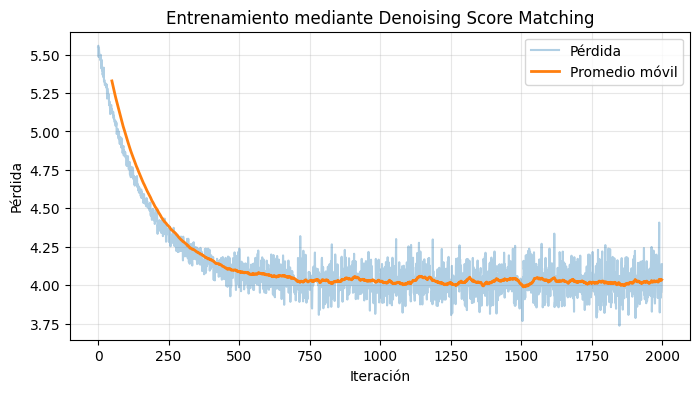

In [ ]:

# Configuración del entrenamiento
n_pasos = 2000
batch_size = 32

# Generador independiente para entrenamiento
rng_train = np.random.default_rng(123)

# Historial
historia = []

for paso in range(n_pasos):

    # 1. Seleccionar un lote de imágenes
    indices = rng_train.integers(0, len(datos), size=batch_size)
    X = datos[indices]

    # 2. Añadir ruido gaussiano nuevo
    epsilon = rng_train.normal(
        0, sigma, size=X.shape
    ).astype(np.float32)

    Y = X + epsilon

    # 3. Score objetivo
    S_objetivo = -epsilon / sigma**2

    # 4. Score predicho
    S_predicho = a * Y + B

    # 5. Función de pérdida
    error = S_predicho - S_objetivo
    loss = 0.5 * np.mean(error**2)

    # 6. Gradientes
    grad_a = np.mean(error * Y)
    grad_B = np.mean(error, axis=0) / D

    # 7. Actualización
    a -= lr_a * grad_a
    B -= lr_B * grad_B

    historia.append(float(loss))

    if (paso + 1) % 200 == 0:
        print(f"Paso {paso + 1:4d} | Pérdida = {loss:.6f}")

print(f"\nParámetro a aprendido: {a:.6f}")

# Visualización de la pérdida
plt.figure(figsize=(8, 4))
plt.plot(historia, alpha=0.35, label="Pérdida")

ventana = 50
promedio = np.convolve(
    historia, np.ones(ventana)/ventana, mode="valid"
)

plt.plot(
    np.arange(ventana - 1, n_pasos),
    promedio,
    linewidth=2,
    label="Promedio móvil"
)

plt.xlabel("Iteración")
plt.ylabel("Pérdida")
plt.title("Entrenamiento mediante Denoising Score Matching")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


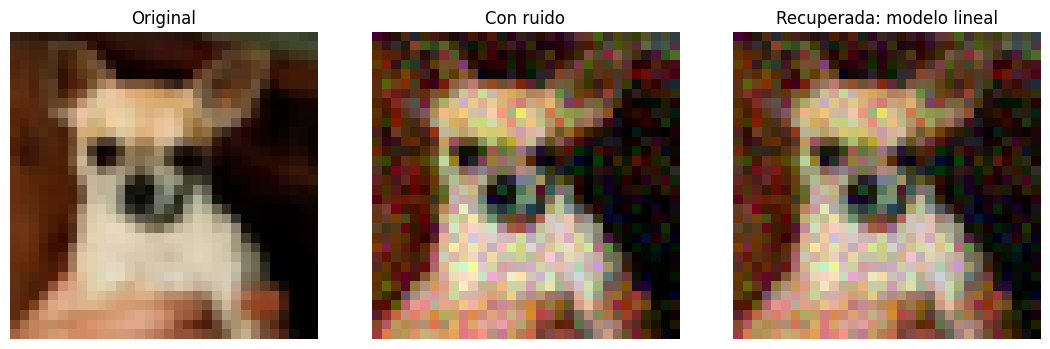

MSE con ruido:  0.022296
MSE recuperada: 0.021010
Reducción del error: 5.77%


In [ ]:

# Seleccionar imagen del conjunto de evaluación
X = evaluacion[4]

# Generar ruido nuevo y reproducible
rng_eval = np.random.default_rng(456)

epsilon = rng_eval.normal(
    0, sigma, size=X.shape
).astype(np.float32)

# Imagen perturbada
Y = X + epsilon

# Score aprendido
S_predicho = a * Y + B

# Reconstrucción
X_recuperada = Y + sigma**2 * S_predicho

# Comparación visual
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))

imagenes = [X, Y, X_recuperada]
titulos = ["Original", "Con ruido", "Recuperada: modelo lineal"]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Evaluación cuantitativa
mse_ruido = np.mean((Y - X)**2)
mse_recuperada = np.mean((X_recuperada - X)**2)
mejora = 100 * (1 - mse_recuperada / mse_ruido)

print(f"MSE con ruido:  {mse_ruido:.6f}")
print(f"MSE recuperada: {mse_recuperada:.6f}")
print(f"Reducción del error: {mejora:.2f}%")


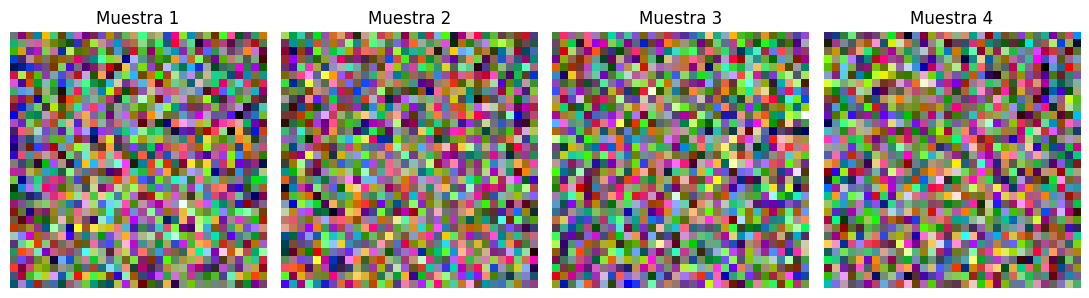

Parámetro a: -3.06398
Paso temporal: 0.016319


In [ ]:

# Generador reproducible
rng_generacion = np.random.default_rng(123)

# Verificar estabilidad del modelo
if a >= 0:
    raise ValueError("Se requiere a < 0 para un campo lineal estable.")

# Inicializar cuatro imágenes con ruido gaussiano
Y = rng_generacion.normal(
    0, 1, size=(4,) + B.shape
).astype(np.float32)

# Parámetros de Langevin
dt = 0.05 / abs(a)
n_pasos = 1000

# Verificar estabilidad numérica
assert 0 < dt * abs(a) < 2

# Evolución estocástica
for paso in range(n_pasos):

    # Score aprendido
    S = a * Y + B

    # Ruido gaussiano independiente
    Z = rng_generacion.normal(
        0, 1, size=Y.shape
    ).astype(np.float32)

    # Actualización de Langevin
    Y += dt * S + np.sqrt(2 * dt) * Z

# Visualizar imágenes generadas
fig, axes = plt.subplots(1, 4, figsize=(11, 3))

for i, ax in enumerate(axes):
    imagen = np.clip((Y[i] + 1) / 2, 0, 1)
    ax.imshow(imagen)
    ax.set_title(f"Muestra {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Parámetro a: {a:.5f}")
print(f"Paso temporal: {dt:.6f}")


In [ ]:

# Generador reproducible
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Se necesita a < 0 para estabilidad.")

# Número de muestras
n_muestras = 200

# Inicialización desde ruido gaussiano
Y = rng.normal(
    size=(n_muestras,) + B.shape
).astype(np.float32)

# Parámetros de Langevin
dt = 0.05 / abs(a)
n_pasos = 1000

# Evolución estocástica
for paso in range(n_pasos):
    S = a * Y + B

    Z = rng.normal(
        size=Y.shape
    ).astype(np.float32)

    Y += dt*S + np.sqrt(2*dt)*Z

# Media experimental
promedio = Y.mean(axis=0)

# Media teórica del modelo
media_modelo = -B / a

# Comparación cuantitativa
error_media = np.mean((promedio - media_modelo)**2)

print(f"MSE entre las medias: {error_media:.6f}")
print(f"Media global simulada: {promedio.mean():.6f}")
print(f"Media global teórica:  {media_modelo.mean():.6f}")


MSE entre las medias: 0.001742
Media global simulada: -0.075652
Media global teórica:  -0.074719


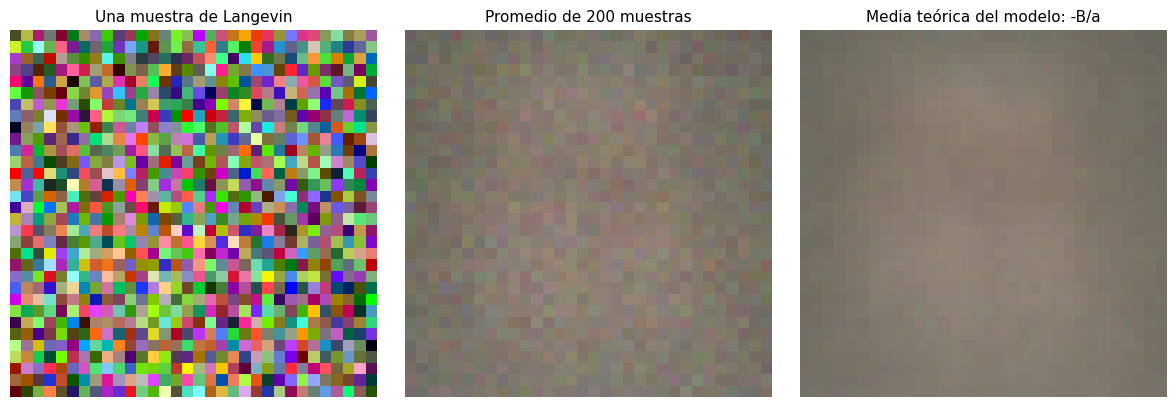

MSE entre las medias: 0.001742


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

imagenes = [Y[0], promedio, media_modelo]

titulos = [
    "Una muestra de Langevin",
    f"Promedio de {n_muestras} muestras",
    "Media teórica del modelo: -B/a"
]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    imagen_rgb = np.clip((imagen + 1) / 2, 0, 1)

    ax.imshow(imagen_rgb, interpolation="nearest")
    ax.set_title(titulo, fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Diferencia entre las dos medias
diferencia = np.mean((promedio - media_modelo)**2)
print(f"MSE entre las medias: {diferencia:.6f}")

In [ ]:
%pip install -q pillow numpy matplotlib

In [ ]:
try:
    from datasets import load_dataset
except ImportError:
    %pip install -q datasets
    from datasets import load_dataset

from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
import json

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# Parámetros
N = 100
TAMANO = 64

carpeta = Path("flores_64")
carpeta.mkdir(parents=True, exist_ok=True)


def procesar_imagen(img, tamano):
    """Convierte una imagen a RGB y tamaño fijo."""

    if isinstance(img, dict):
        contenido = img.get("bytes") or img.get("content")

        if contenido is None:
            raise ValueError("No se encontraron bytes de imagen.")

        img = Image.open(BytesIO(contenido))

    elif not isinstance(img, Image.Image):
        img = Image.fromarray(np.asarray(img))

    img = img.convert("RGB")
    img = ImageOps.fit(img, (tamano, tamano))

    return np.asarray(img, dtype=np.float32) / 255.0


def cargar_flores(n=100, tamano=64):
    """Carga imágenes de Oxford Flowers."""

    try:
        ds = load_dataset(
            "nkirschi/oxford-flowers",
            split=f"train[:{n}]"
        )

        imagenes = [
            procesar_imagen(ejemplo["image"], tamano)
            for ejemplo in ds
        ]

    except Exception as e:
        print(f"Error en carga directa: {e}")
        print("Intentando descarga alternativa...")

        url = (
            "https://datasets-server.huggingface.co/rows?"
            "dataset=nkirschi/oxford-flowers"
            "&config=default&split=train"
            f"&offset=0&length={n}"
        )

        with urlopen(url, timeout=60) as respuesta:
            filas = json.load(respuesta)["rows"]

        imagenes = []

        for i, fila in enumerate(filas):
            archivo = carpeta / f"flor_{i:03d}_{tamano}.png"

            if archivo.exists():
                with Image.open(archivo) as img:
                    imagen = procesar_imagen(img, tamano)
            else:
                src = fila["row"]["image"]["src"]

                with urlopen(src, timeout=60) as respuesta:
                    contenido = respuesta.read()

                imagen = procesar_imagen(
                    Image.open(BytesIO(contenido)),
                    tamano
                )

                Image.fromarray(
                    (imagen * 255).astype(np.uint8)
                ).save(archivo)

            imagenes.append(imagen)

    if len(imagenes) != n:
        raise ValueError(
            f"Se solicitaron {n} imágenes, "
            f"pero se cargaron {len(imagenes)}."
        )

    return np.stack(imagenes).astype(np.float32)


# Cargar imágenes
imagenes = cargar_flores(N, TAMANO)

print("Forma:", imagenes.shape)
print("Rango:", imagenes.min(), imagenes.max())
print("Tipo:", imagenes.dtype)

Forma: (100, 64, 64, 3)
Rango: 0.0 1.0
Tipo: float32


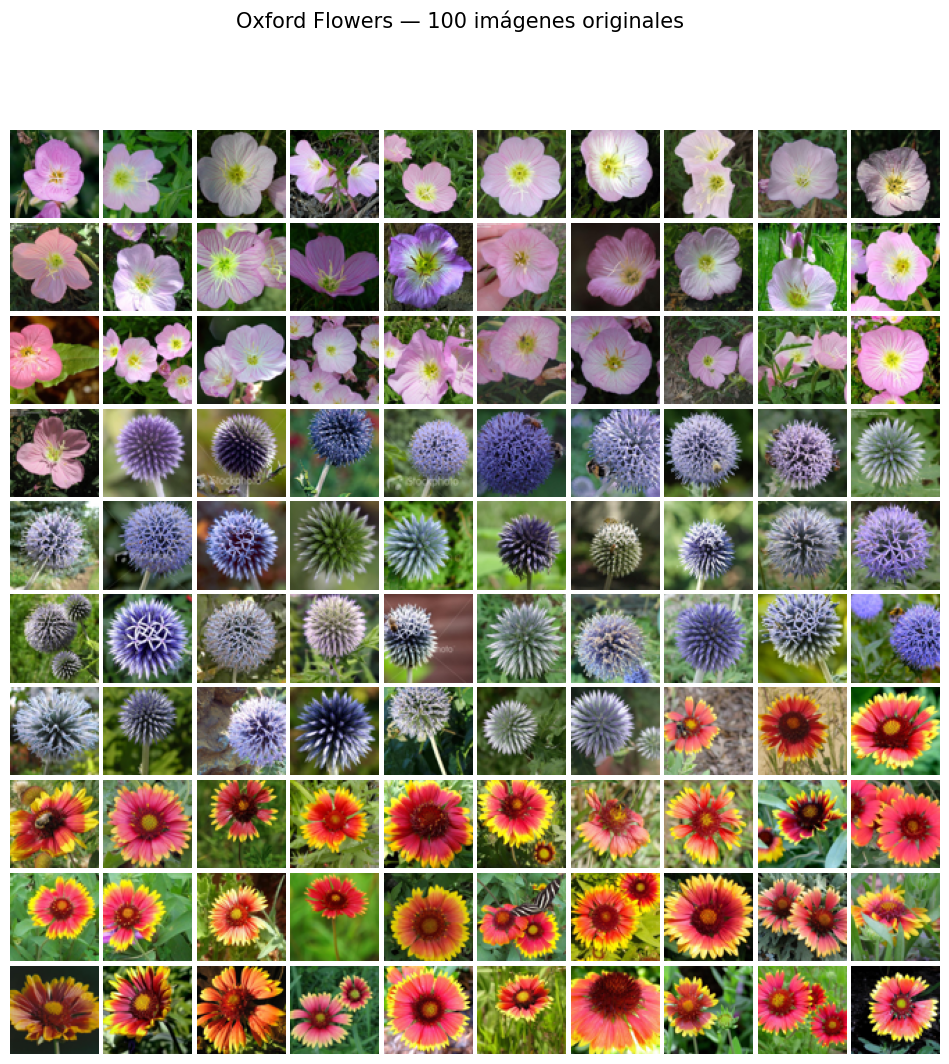

In [ ]:
# Visualizar las primeras 100 flores
fig, ejes = plt.subplots(10, 10, figsize=(12, 12))

for eje, imagen in zip(ejes.flat, imagenes[:100]):
    eje.imshow(imagen)
    eje.axis("off")

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.suptitle("Oxford Flowers — 100 imágenes originales", fontsize=15)
plt.show()

In [ ]:
np.shape(imagenes)

(100, 64, 64, 3)

Entrenamiento: (80, 64, 64, 3)
Test: (20, 64, 64, 3)


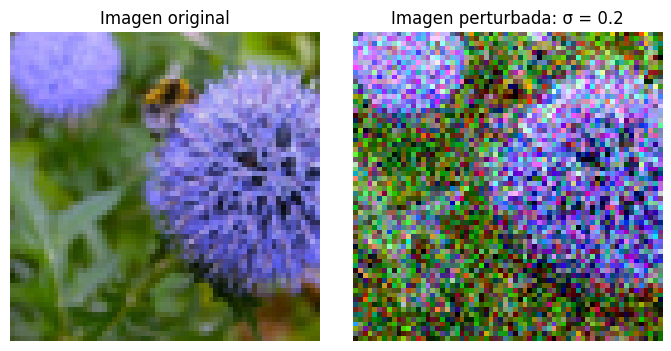

In [ ]:
rng = np.random.default_rng(42)

# 1. Barajar y separar las imágenes
indices = rng.permutation(len(imagenes))
corte = int(0.8 * len(imagenes))

entrenamiento = imagenes[indices[:corte]]
test = imagenes[indices[corte:]]

print("Entrenamiento:", entrenamiento.shape)
print("Test:", test.shape)

# 2. Añadir ruido gaussiano
sigma = 0.20

def perturbar(X, sigma):
    epsilon = rng.normal(
        loc=0.0,
        scale=sigma,
        size=X.shape
    ).astype(np.float32)

    Y = X + epsilon

    return Y, epsilon

entrenamiento_perturbado, ruido_train = perturbar(
    entrenamiento, sigma
)

test_perturbado, ruido_test = perturbar(
    test, sigma
)

# 3. Comparación visual
i = 0

fig, ejes = plt.subplots(1, 2, figsize=(7, 3.5))

ejes[0].imshow(entrenamiento[i])
ejes[0].set_title("Imagen original")

ejes[1].imshow(
    np.clip(entrenamiento_perturbado[i], 0, 1)
)
ejes[1].set_title(f"Imagen perturbada: σ = {sigma}")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

# Debe configurarse antes de importar Keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras import layers

# Reproducibilidad
keras.utils.set_random_seed(42)

# Red neuronal convolucional
modelo = keras.Sequential([
    keras.Input(shape=entrenamiento.shape[1:]),

    layers.Conv2D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),

    layers.Conv2D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),

    # Predicción de tres canales RGB
    layers.Conv2D(
        filters=3,
        kernel_size=3,
        padding="same",
        activation=None
    )
])

# Configuración del entrenamiento
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

modelo.summary()

print("Backend:", keras.backend.backend())
print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,011 (43.01 KB)

 Trainable params: 11,011 (43.01 KB)

 Non-trainable params: 0 (0.00 B)

Backend: torch
Entrada: (None, 64, 64, 3)
Salida: (None, 64, 64, 3)


In [ ]:
# Parámetros de entrenamiento
sigma = 0.15
n_epocas = 20
batch_size = 8

perdidas_train = []
perdidas_test = []

# Evaluación con ruido fijo
test_perturbado, ruido_test = perturbar(test, sigma)

for epoca in range(n_epocas):

    # 1. Generar ruido nuevo para entrenamiento
    entradas, ruido_real = perturbar(entrenamiento, sigma)

    # 2. Entrenar la red neuronal
    historia = modelo.fit(
        entradas,
        ruido_real,
        epochs=1,
        batch_size=batch_size,
        shuffle=True,
        verbose=0
    )

    mse_train = historia.history["loss"][0]

    # 3. Evaluar sin modificar los pesos
    mse_test = modelo.evaluate(
        test_perturbado,
        ruido_test,
        batch_size=batch_size,
        verbose=0
    )

    # 4. Guardar resultados
    perdidas_train.append(float(mse_train))
    perdidas_test.append(float(mse_test))

    print(
        f"Época {epoca + 1:02d}/{n_epocas} | "
        f"Train: {mse_train:.6f} | "
        f"Test: {mse_test:.6f}"
    )

# 5. Visualizar el aprendizaje
epocas = np.arange(1, n_epocas + 1)

plt.figure(figsize=(8, 4))

plt.plot(epocas, perdidas_train, "o-", label="Entrenamiento")
plt.plot(epocas, perdidas_test, "s-", label="Evaluación")

plt.axhline(
    sigma**2,
    linestyle="--",
    color="gray",
    label="Referencia: varianza del ruido"
)

plt.xlabel("Época")
plt.ylabel("Error cuadrático medio (MSE)")
plt.title("Aprendizaje de predicción de ruido")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Época 01/20 | Train: 0.9639 | Test: 0.9162
Época 02/20 | Train: 0.8600 | Test: 0.7758
Época 03/20 | Train: 0.7071 | Test: 0.6207
Época 04/20 | Train: 0.5556 | Test: 0.4760
Época 05/20 | Train: 0.4208 | Test: 0.3639
Época 06/20 | Train: 0.3305 | Test: 0.2967
Época 07/20 | Train: 0.2782 | Test: 0.2580
Época 08/20 | Train: 0.2504 | Test: 0.2358
Época 09/20 | Train: 0.2335 | Test: 0.2245
Época 10/20 | Train: 0.2252 | Test: 0.2185
Época 11/20 | Train: 0.2203 | Test: 0.2141
Época 12/20 | Train: 0.2172 | Test: 0.2098
Época 13/20 | Train: 0.2133 | Test: 0.2073
Época 14/20 | Train: 0.2111 | Test: 0.2058
Época 15/20 | Train: 0.2097 | Test: 0.2049
Época 16/20 | Train: 0.2090 | Test: 0.2031
Época 17/20 | Train: 0.2084 | Test: 0.2030
Época 18/20 | Train: 0.2066 | Test: 0.2023
Época 19/20 | Train: 0.2062 | Test: 0.2016
Época 20/20 | Train: 0.2056 | Test: 0.2046


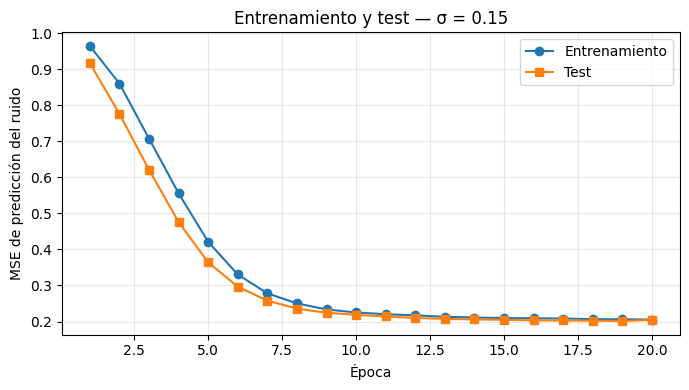

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(epocas, perdidas_train, "o-", label="Entrenamiento")
plt.plot(epocas, perdidas_test, "s-", label="Test")

# Referencia: predictor que siempre devuelve ruido cero
plt.axhline(
    y=sigma**2,
    color="gray",
    linestyle="--",
    label=f"Referencia: σ² = {sigma**2:.4f}"
)

plt.xlabel("Época")
plt.ylabel("MSE de predicción del ruido")
plt.title(f"Entrenamiento y evaluación — σ = {sigma}")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

MSE antes:   0.039852
MSE después: 0.049158
Mejora:      -23.35%


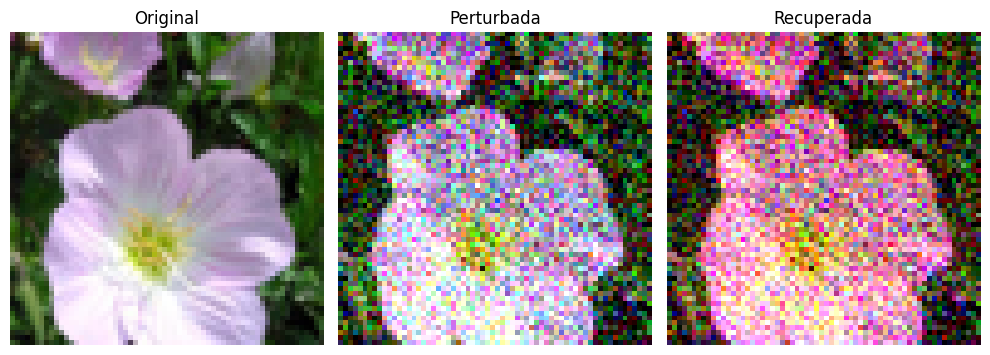

In [ ]:
# 1. Predecir el ruido de las imágenes de prueba
ruido_predicho = modelo.predict(
    test_perturbado,
    batch_size=8,
    verbose=0
)

# 2. Reconstruir las imágenes
# La red predice epsilon, que ya incluye sigma.
recuperadas = test_perturbado - ruido_predicho

# 3. Calcular errores
mse_antes = np.mean((test_perturbado - test)**2)
mse_despues = np.mean((recuperadas - test)**2)

mejora = 100 * (1 - mse_despues / mse_antes)

print(f"MSE antes:   {mse_antes:.6f}")
print(f"MSE después: {mse_despues:.6f}")
print(f"Mejora:      {mejora:.2f}%")

# 4. Visualizar una flor
i = 3

fig, ejes = plt.subplots(1, 3, figsize=(10, 3.5))

comparacion = [
    (test[i], "Original"),
    (test_perturbado[i], "Perturbada"),
    (recuperadas[i], "Recuperada")
]

for eje, (imagen, titulo) in zip(ejes, comparacion):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [ ]:


import torch

n_imagenes = 9
n_pasos = 5000

rng_generacion = np.random.default_rng(123)

# Paso temporal de Langevin
h = np.float32(0.005 * sigma**2)
amplitud = np.float32(np.sqrt(2 * h))

# Inicialización independiente de las flores originales
forma = tuple(modelo.input_shape[1:])

generadas = rng_generacion.uniform(
    0, 1, size=(n_imagenes, *forma)
).astype(np.float32)

# Guardar la evolución de la primera imagen
evolucion = {0: generadas[0].copy()}
guardar_en = {50, 100, 250, 1000, 2500, n_pasos}

# Los pesos permanecen fijos durante la generación
with torch.no_grad():

    for paso in range(1, n_pasos + 1):

        # La red estima el ruido epsilon
        ruido_predicho = keras.ops.convert_to_numpy(
            modelo(generadas, training=False)
        )

        # Score estimado: corrección matemática
        score = -ruido_predicho / sigma**2

        # Ruido gaussiano nuevo
        z = rng_generacion.normal(
            0, 1, size=generadas.shape
        ).astype(np.float32)

        # Dinámica de Langevin
        generadas += h * score + amplitud * z

        # Guardar estados intermedios
        if paso in guardar_en:
            evolucion[paso] = generadas[0].copy()

        # Verificar estabilidad
        if paso % 500 == 0:

            if not np.isfinite(generadas).all():
                raise FloatingPointError(
                    "La dinámica diverge. Reduce h."
                )

            print(f"Paso {paso}/{n_pasos}")

print("Generación finalizada.")
print("Forma:", generadas.shape)
print("Rango:", generadas.min(), generadas.max())

Paso 500/5000
Paso 1000/5000
Paso 1500/5000
Paso 2000/5000
Paso 2500/5000
Paso 3000/5000
Paso 3500/5000
Paso 4000/5000
Paso 4500/5000
Paso 5000/5000
Generación finalizada.
Forma: (9, 64, 64, 3)
Rango: -169.79103 130.85062


In [ ]:
# Mostrar las nueve imágenes finales.
fig, ejes = plt.subplots(3, 3, figsize=(8, 8))

for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(generadas[i], 0, 1))
    eje.set_title(f"Muestra {i + 1}")
    eje.axis("off")

fig.suptitle(f"Generación con σ = {float(sigma):.2f}")
plt.tight_layout()
plt.show()

# Mostrar cómo evolucionó la primera imagen.
fig, ejes = plt.subplots(
    1, len(evolucion), figsize=(3 * len(evolucion), 3)
)

for eje, (paso, imagen) in zip(ejes, evolucion.items()):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(f"Paso {paso}")
    eje.axis("off")

plt.tight_layout()
plt.show()


Tarea laboratorio es : Implementar una red tipo Unet, para generar imagenes con una mejor aproximación

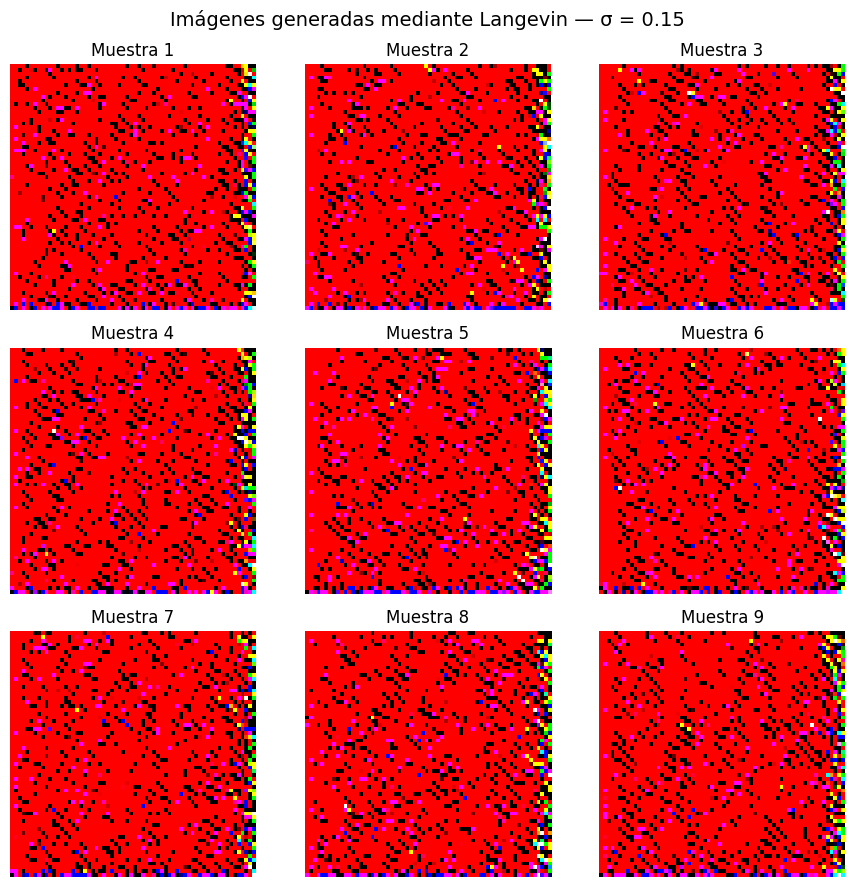

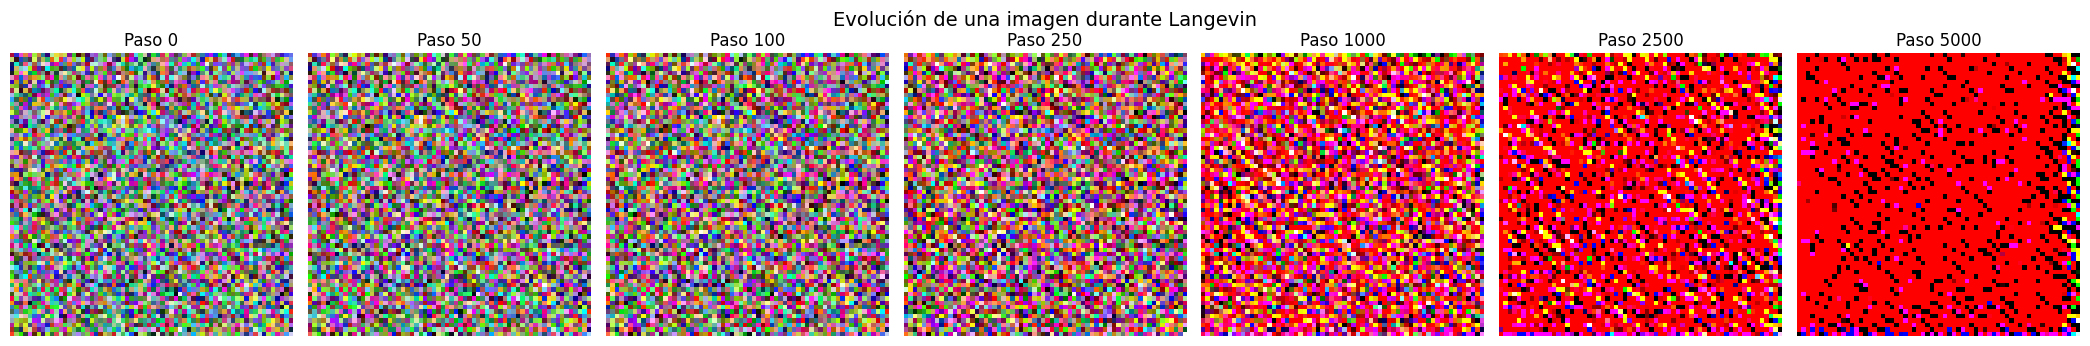

In [ ]:
# 1. Mostrar las nueve imágenes finales
fig, ejes = plt.subplots(3, 3, figsize=(9, 9))

for i, eje in enumerate(ejes.flat):
    eje.imshow(
        np.clip(generadas[i], 0, 1),
        interpolation="nearest"
    )
    eje.set_title(f"Muestra {i + 1}")
    eje.axis("off")

fig.suptitle(
    f"Imágenes generadas mediante Langevin — σ = {sigma:.2f}",
    fontsize=14
)

plt.tight_layout()
plt.show()


# 2. Visualizar la evolución de la primera imagen
pasos_guardados = sorted(evolucion.keys())

fig, ejes = plt.subplots(
    1,
    len(pasos_guardados),
    figsize=(3 * len(pasos_guardados), 3.5)
)

for eje, paso in zip(ejes, pasos_guardados):

    imagen = evolucion[paso]

    eje.imshow(
        np.clip(imagen, 0, 1),
        interpolation="nearest"
    )

    eje.set_title(f"Paso {paso}")
    eje.axis("off")

fig.suptitle("Evolución de una imagen durante Langevin", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
import keras
from keras import layers

keras.utils.set_random_seed(42)

def bloque_conv(x, filtros):
    x = layers.Conv2D(
        filtros, 3, padding="same", activation="relu"
    )(x)
    x = layers.Conv2D(
        filtros, 3, padding="same", activation="relu"
    )(x)
    return x


def crear_unet():
    entrada = keras.Input(shape=(64, 64, 3))

    # Codificador
    c1 = bloque_conv(entrada, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = bloque_conv(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    # Cuello de botella
    centro = bloque_conv(p2, 128)

    # Decodificador
    u2 = layers.UpSampling2D((2, 2))(centro)
    u2 = layers.Concatenate()([u2, c2])
    c3 = bloque_conv(u2, 64)

    u1 = layers.UpSampling2D((2, 2))(c3)
    u1 = layers.Concatenate()([u1, c1])
    c4 = bloque_conv(u1, 32)

    # Predicción del ruido RGB
    salida = layers.Conv2D(
        3, 1, padding="same", activation="linear"
    )(c4)

    return keras.Model(entrada, salida, name="UNet_Flores")


modelo_unet = crear_unet()

modelo_unet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

modelo_unet.summary()

Model: "UNet_Flores"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_6[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 16, 16,    │    147,584 │ conv2d_10[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_11[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 32, 32,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_12[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_13[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64,    │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 64, 64,    │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_14[0][0] 

 Total params: 471,619 (1.80 MB)

 Trainable params: 471,619 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
sigma = 0.15
n_epocas_unet = 50
batch_size = 8

perdidas_unet_train = []
perdidas_unet_test = []

rng_unet = np.random.default_rng(2026)

def perturbar_unet(X, sigma):
    epsilon = rng_unet.normal(
        0, sigma, size=X.shape
    ).astype(np.float32)

    return X + epsilon, epsilon

# Evaluación con perturbación fija
test_ruidoso_unet, ruido_test_unet = perturbar_unet(
    test, sigma
)

for epoca in range(n_epocas_unet):

    # Ruido nuevo en cada época
    entradas, ruido_real = perturbar_unet(
        entrenamiento, sigma
    )

    historia_unet = modelo_unet.fit(
        entradas,
        ruido_real,
        epochs=1,
        batch_size=batch_size,
        shuffle=True,
        verbose=0
    )

    mse_train = historia_unet.history["loss"][0]

    mse_test = modelo_unet.evaluate(
        test_ruidoso_unet,
        ruido_test_unet,
        batch_size=batch_size,
        verbose=0
    )

    perdidas_unet_train.append(float(mse_train))
    perdidas_unet_test.append(float(mse_test))

    if (epoca + 1) % 5 == 0:
        print(
            f"Época {epoca+1:02d}/{n_epocas_unet} | "
            f"Train: {mse_train:.6f} | "
            f"Test: {mse_test:.6f}"
        )

Época 05/50 | Train: 0.003886 | Test: 0.003730
Época 10/50 | Train: 0.003806 | Test: 0.003803
Época 15/50 | Train: 0.003737 | Test: 0.003613
Época 20/50 | Train: 0.003661 | Test: 0.003535
Época 25/50 | Train: 0.003682 | Test: 0.003530
Época 30/50 | Train: 0.003611 | Test: 0.003454
Época 35/50 | Train: 0.003599 | Test: 0.003432
Época 40/50 | Train: 0.003502 | Test: 0.003376
Época 45/50 | Train: 0.003536 | Test: 0.003391
Época 50/50 | Train: 0.003530 | Test: 0.003370


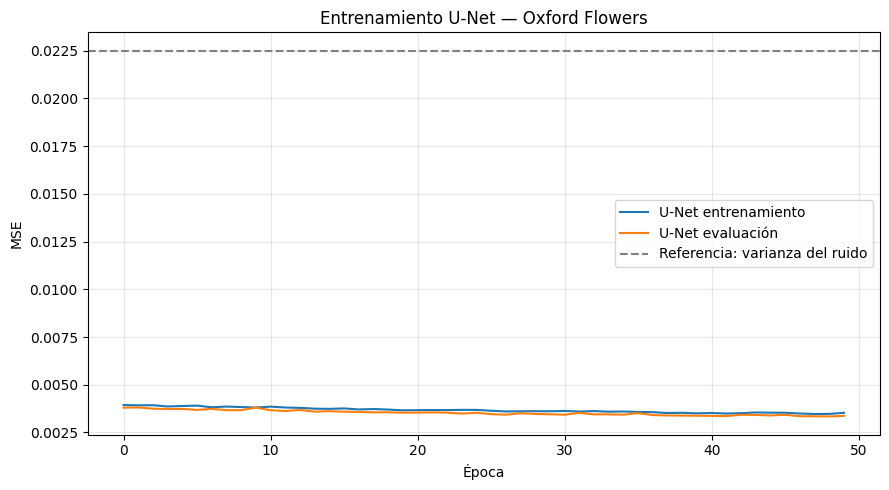

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    perdidas_unet_train,
    label="U-Net entrenamiento"
)

plt.plot(
    perdidas_unet_test,
    label="U-Net evaluación"
)

plt.axhline(
    sigma**2,
    color="gray",
    linestyle="--",
    label="Referencia: varianza del ruido"
)

plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Entrenamiento U-Net — Oxford Flowers")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

MSE imagen ruidosa: 0.022467
MSE CNN anterior:   0.031028
MSE U-Net:          0.003370


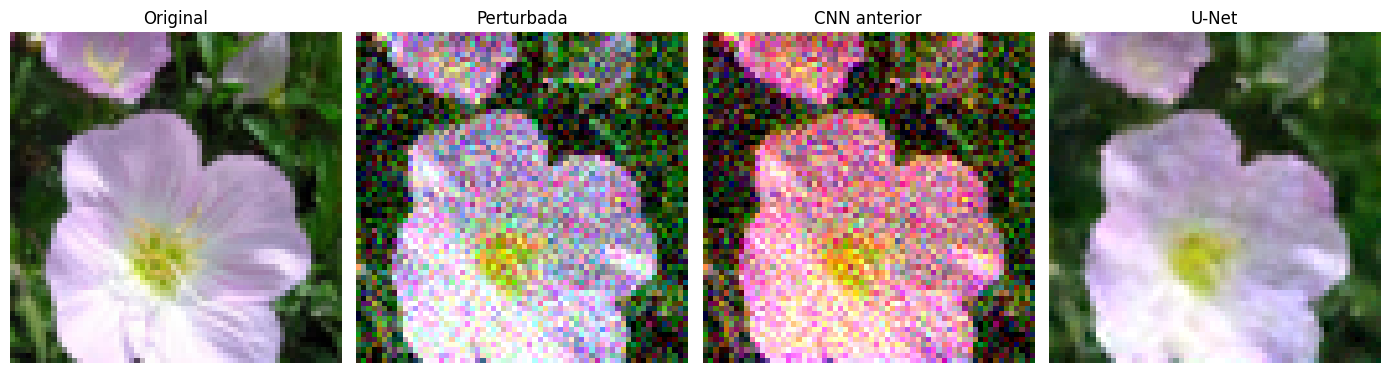

In [ ]:
# Predicción con CNN anterior
ruido_cnn = modelo.predict(
    test_ruidoso_unet,
    batch_size=8,
    verbose=0
)

# Predicción con U-Net
ruido_unet = modelo_unet.predict(
    test_ruidoso_unet,
    batch_size=8,
    verbose=0
)

# Reconstrucciones
recuperadas_cnn = test_ruidoso_unet - ruido_cnn
recuperadas_unet = test_ruidoso_unet - ruido_unet

# Errores
mse_ruidoso = np.mean((test_ruidoso_unet - test)**2)
mse_cnn = np.mean((recuperadas_cnn - test)**2)
mse_unet = np.mean((recuperadas_unet - test)**2)

print(f"MSE imagen ruidosa: {mse_ruidoso:.6f}")
print(f"MSE CNN anterior:   {mse_cnn:.6f}")
print(f"MSE U-Net:          {mse_unet:.6f}")

# Visualización
i = 3

fig, ejes = plt.subplots(1, 4, figsize=(14, 4))

imagenes_comparacion = [
    test[i],
    test_ruidoso_unet[i],
    recuperadas_cnn[i],
    recuperadas_unet[i]
]

titulos = [
    "Original",
    "Perturbada",
    "CNN anterior",
    "U-Net"
]

for eje, imagen, titulo in zip(
    ejes, imagenes_comparacion, titulos
):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch

rng_generacion = np.random.default_rng(123)

n_imagenes = 9
n_pasos = 5000

h = np.float32(0.005 * sigma**2)
amplitud = np.float32(np.sqrt(2*h))

generadas_unet = rng_generacion.uniform(
    0, 1, size=(n_imagenes, 64, 64, 3)
).astype(np.float32)

evolucion_unet = {0: generadas_unet[0].copy()}
guardar_en = {100, 500, 1000, 2500, 5000}

with torch.no_grad():

    for paso in range(1, n_pasos + 1):

        ruido_predicho = keras.ops.convert_to_numpy(
            modelo_unet(generadas_unet, training=False)
        )

        score = -ruido_predicho / sigma**2

        z = rng_generacion.normal(
            size=generadas_unet.shape
        ).astype(np.float32)

        generadas_unet += h*score + amplitud*z

        if paso in guardar_en:
            evolucion_unet[paso] = generadas_unet[0].copy()

        if paso % 500 == 0:
            if not np.isfinite(generadas_unet).all():
                raise FloatingPointError(
                    "La dinámica diverge. Reduce h."
                )
            print(f"Paso {paso}/{n_pasos}")

Paso 500/5000
Paso 1000/5000
Paso 1500/5000
Paso 2000/5000
Paso 2500/5000
Paso 3000/5000
Paso 3500/5000
Paso 4000/5000
Paso 4500/5000
Paso 5000/5000


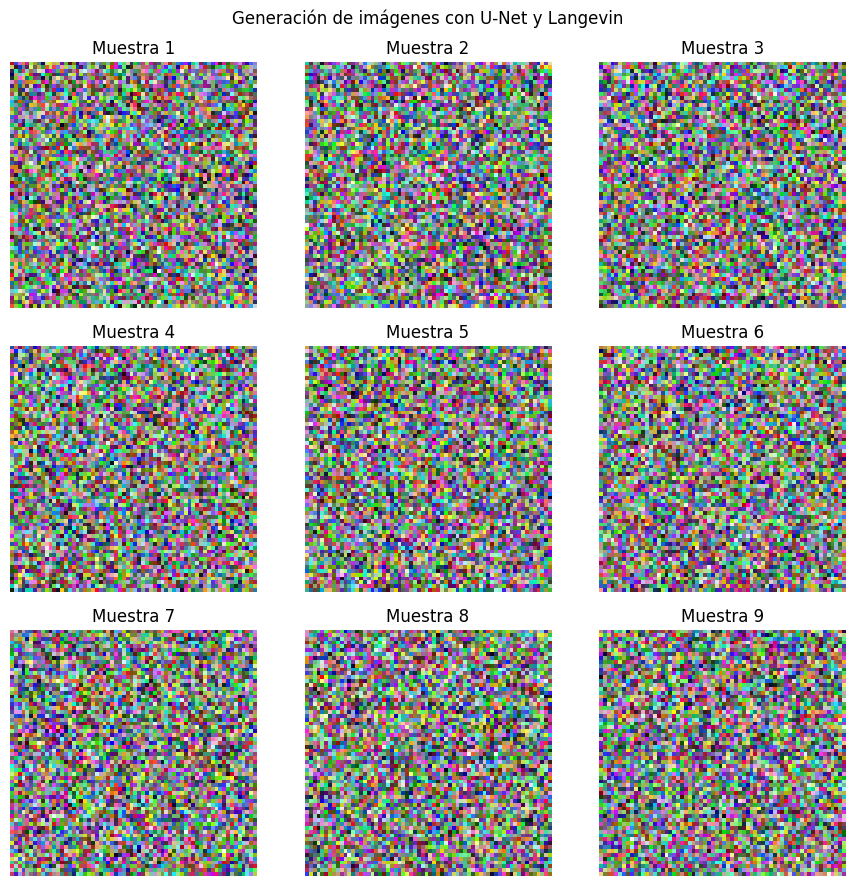

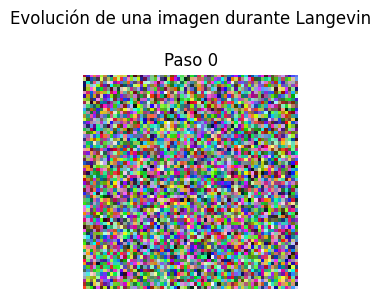

Pasos disponibles: [0]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. MOSTRAR LAS NUEVE IMÁGENES GENERADAS
# ==========================================

fig, ejes = plt.subplots(3, 3, figsize=(9, 9))

for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(generadas_unet[i], 0, 1))
    eje.set_title(f"Muestra {i + 1}")
    eje.axis("off")

fig.suptitle("Generación de imágenes con U-Net y Langevin")

plt.tight_layout()
plt.show()


# ==========================================
# 2. MOSTRAR LA EVOLUCIÓN DE LA PRIMERA IMAGEN
# ==========================================

pasos = sorted(evolucion_unet.keys())

fig, ejes = plt.subplots(
    1,
    len(pasos),
    figsize=(3 * len(pasos), 3),
    squeeze=False
)

# Convertir los ejes en un arreglo unidimensional
ejes = ejes.flatten()

for eje, paso in zip(ejes, pasos):
    imagen = evolucion_unet[paso]

    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(f"Paso {paso}")
    eje.axis("off")

fig.suptitle("Evolución de una imagen durante Langevin")

plt.tight_layout()
plt.show()

print("Pasos disponibles:", pasos)

## Conclusiones

En este laboratorio se estudió la generación y reconstrucción de imágenes mediante **Denoising Score Matching (DSM)** y dinámica de Langevin, utilizando imágenes reales del conjunto de datos Oxford Flowers.

Inicialmente, se implementó una red neuronal convolucional sencilla para estimar el ruido gaussiano añadido a las imágenes. Posteriormente, se desarrolló una arquitectura **U-Net**, con el propósito de mejorar la capacidad del modelo para identificar estructuras espaciales, bordes, colores y texturas.

A partir del desarrollo computacional se establecen las siguientes conclusiones:

1. **El Denoising Score Matching permite aproximar el score de una distribución de datos.** Al entrenar una red neuronal para estimar la perturbación gaussiana, es posible construir una aproximación al gradiente del logaritmo de la densidad de probabilidad de las imágenes perturbadas.

2. **La arquitectura U-Net ofrece una representación más completa de las imágenes que una CNN sencilla.** Su estructura de codificación y decodificación, junto con las conexiones de salto, permite combinar información espacial a distintas escalas. Esto proporciona una arquitectura adecuada para tareas de eliminación de ruido, aunque la mejora efectiva debe verificarse mediante los resultados experimentales.

3. **La reconstrucción de imágenes está relacionada directamente con el score aprendido.** La estimación del ruido permite recuperar una aproximación de la imagen original mediante la expresión:

   $$
   \hat{X}=Y-f_\theta(Y),
   $$

   donde $Y$ representa la imagen perturbada y $f_\theta(Y)$ corresponde al ruido estimado por la red neuronal.

4. **La dinámica de Langevin conecta el aprendizaje automático con los procesos estocásticos de la física.** Su evolución combina un término determinista, asociado al score aprendido, y un término aleatorio, correspondiente a las fluctuaciones gaussianas. Esta combinación permite explorar la distribución de probabilidad representada por el modelo.

5. **La calidad de la reconstrucción y la generación de imágenes son problemas relacionados, pero diferentes.** Una red neuronal puede aprender a eliminar ruido de imágenes conocidas sin necesariamente generar imágenes realistas a partir de condiciones iniciales aleatorias.

6. **El entrenamiento con un único nivel de ruido constituye una limitación del modelo implementado.** Para mejorar la generación de imágenes, sería conveniente entrenar una U-Net condicionada por diferentes valores de $\sigma$ e implementar una dinámica de Langevin con niveles de ruido progresivamente decrecientes.

### Conclusión general

El laboratorio permitió comprender cómo una red neuronal puede utilizarse para aproximar información estadística de una distribución de imágenes y cómo esta información puede incorporarse en una dinámica estocástica para realizar reconstrucción y generación.

La implementación de una U-Net representa un avance metodológico respecto al modelo convolucional inicial, debido a su capacidad para procesar características espaciales a diferentes escalas. Sin embargo, determinar si proporciona mejores resultados requiere comparar cuantitativamente los errores de reconstrucción y analizar visualmente las imágenes generadas.

Desde el punto de vista de la física computacional, el resultado más importante es la conexión entre **gradientes de densidades de probabilidad, aprendizaje profundo y ecuaciones diferenciales estocásticas**, que constituye uno de los fundamentos de los modelos generativos modernos.